<a href="https://colab.research.google.com/github/Maniganiga404/AML/blob/main/MidTermAML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
pip install ucimlrepo

In [11]:

from ucimlrepo import fetch_ucirepo

# Download the exact UCI dataset (ID 17)
dataset = fetch_ucirepo(id=17)

# Get the input features and target
X = dataset.data.features
y = dataset.data.targets

# Display the first 5 rows
print("First 5 rows of features:")
print(X.head())

print("\nFirst 5 target values:")
print(y.head())

# Display dataset dimensions
print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

# Display all column names
print("\nColumn names:")
print(X.columns.tolist())

# Display class counts
print("\nClass distribution:")
print(y["Diagnosis"].value_counts())


First 5 rows of features:
   radius1  texture1  perimeter1   area1  smoothness1  compactness1  \
0    17.99     10.38      122.80  1001.0      0.11840       0.27760   
1    20.57     17.77      132.90  1326.0      0.08474       0.07864   
2    19.69     21.25      130.00  1203.0      0.10960       0.15990   
3    11.42     20.38       77.58   386.1      0.14250       0.28390   
4    20.29     14.34      135.10  1297.0      0.10030       0.13280   

   concavity1  concave_points1  symmetry1  fractal_dimension1  ...  radius3  \
0      0.3001          0.14710     0.2419             0.07871  ...    25.38   
1      0.0869          0.07017     0.1812             0.05667  ...    24.99   
2      0.1974          0.12790     0.2069             0.05999  ...    23.57   
3      0.2414          0.10520     0.2597             0.09744  ...    14.91   
4      0.1980          0.10430     0.1809             0.05883  ...    22.54   

   texture3  perimeter3   area3  smoothness3  compactness3  concavity3  

In [12]:

import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the UCI Breast Cancer Wisconsin Diagnostic dataset
dataset = fetch_ucirepo(id=17)

X = dataset.data.features
y = dataset.data.targets.iloc[:, 0]

# Encode labels: Benign = 0, Malignant = 1
y = y.map({"B": 0, "M": 1})

print("Dataset shape:", X.shape)
print("Target counts:\n", y.value_counts())

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# (a) Train decision trees using Entropy and Gini
dt_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

dt_gini = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

dt_entropy.fit(X_train, y_train)
dt_gini.fit(X_train, y_train)

print("\n(a) Model Comparison")
print("Entropy Accuracy:",
      accuracy_score(y_test, dt_entropy.predict(X_test)))
print("Gini Accuracy:",
      accuracy_score(y_test, dt_gini.predict(X_test)))





Dataset shape: (569, 30)
Target counts:
 Diagnosis
0    357
1    212
Name: count, dtype: int64

(a) Model Comparison
Entropy Accuracy: 0.956140350877193
Gini Accuracy: 0.9298245614035088


In [13]:
# (b) Calculate Entropy and Gini Impurity
benign = 12
malignant = 8
total = benign + malignant

p_benign = benign / total
p_malignant = malignant / total

entropy = -(
    p_benign * np.log2(p_benign)
    + p_malignant * np.log2(p_malignant)
)

gini = 1 - (p_benign ** 2 + p_malignant ** 2)

print("\n(b) Parent Node Impurity")
print("Entropy:", entropy)
print("Gini Impurity:", gini)


(b) Parent Node Impurity
Entropy: 0.9709505944546686
Gini Impurity: 0.48



(c) Evaluation Metrics
Accuracy: 0.956140350877193
Precision: 0.9743589743589743
Recall: 0.9047619047619048
F1-score: 0.9382716049382716

Confusion Matrix:
 [[71  1]
 [ 4 38]]


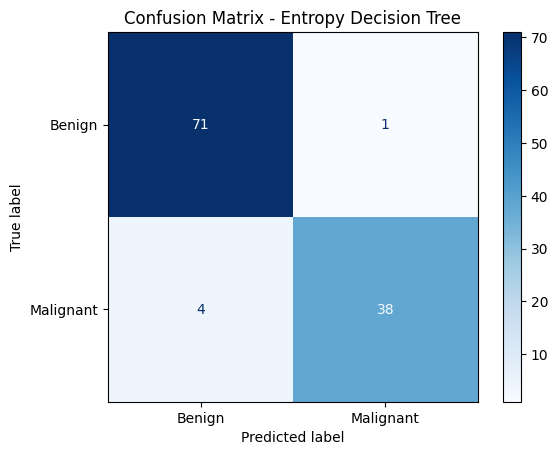

In [14]:
# (c) Evaluate the Entropy classifier
y_pred = dt_entropy.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\n(c) Evaluation Metrics")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("\nConfusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Entropy Decision Tree")
plt.show()

In [15]:

# (d) Explain and justify the most important metric using results

tn, fp, fn, tp = cm.ravel()

print("\n(d) Justification using Evaluation Results")

print("Recall:", recall)
print("False Negatives:", fn)
print("True Positives:", tp)

if tp + fn > 0:
    print("Percentage of malignant cases detected:", recall * 100, "%")

if fn > 0:
    print("The model missed", fn, "malignant cases.")
else:
    print("The model did not miss any malignant cases.")

print("False Positive cases:", fp)



(d) Justification using Evaluation Results
Recall: 0.9047619047619048
False Negatives: 4
True Positives: 38
Percentage of malignant cases detected: 90.47619047619048 %
The model missed 4 malignant cases.
False Positive cases: 1


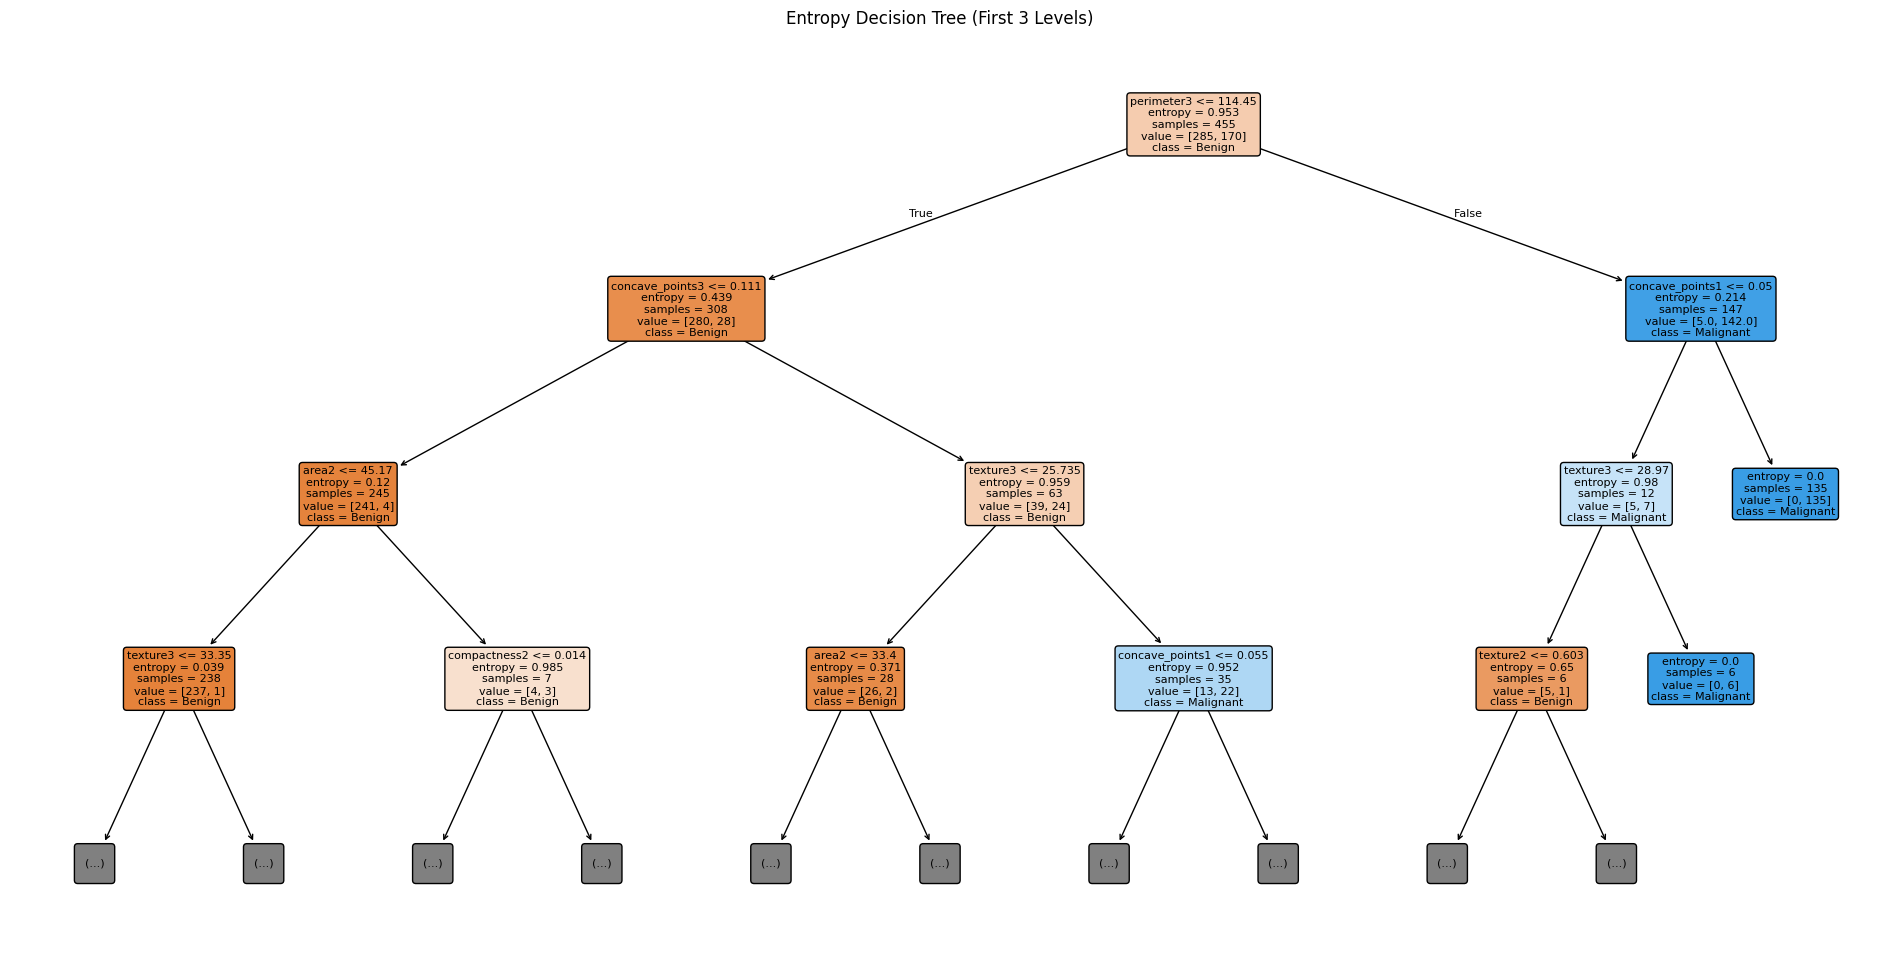

In [16]:
# Additional: Plot the trained decision tree
plt.figure(figsize=(24, 12))

plot_tree(
    dt_entropy,
    feature_names=list(X.columns),
    class_names=["Benign", "Malignant"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Entropy Decision Tree (First 3 Levels)")
plt.show()